# Task 5 — Account Security Monitoring (Anomaly Detection)

**โจทย์:** หาบัญชีที่มีพฤติกรรมผิดปกติ (โดนขโมยบัญชี, bot, ใช้ VPN โกงราคา ฯลฯ) จาก `test.csv` ซึ่ง **ไม่มี label ให้เลย**
จึงต้องใช้วิธี unsupervised ล้วน ๆ

**Metric:** F3 = 10·P·R / (9P + R) → ให้น้ำหนัก recall มากกว่า precision 9 เท่า พลาดบัญชีผิดปกติแย่กว่า flag เกินนิดหน่อย

### Pipeline
1. โหลดข้อมูล
2. EDA — ดูโครงสร้าง 4 ช่วงเวลา, missing values, การกระจายของ feature
3. สร้างสถิติต่อบัญชี — *ระดับปกติ* (median 4 ช่วง) และ *การเปลี่ยนแปลงกะทันหัน* (ช่วง 4 เทียบช่วง 1–3)
4. หา "ช่องว่าง" (gap) ที่หางของการกระจาย → กลุ่มบัญชีที่แยกตัวออกจากคนส่วนใหญ่
5. รวมทุกกลุ่มเป็น flag แล้วตีความว่าเป็นความผิดปกติชนิดไหน
6. เช็คว่าผลไม่ไวต่อพารามิเตอร์
7. เทียบกับ Isolation Forest (วิธีตามคำใบ้ในสไลด์)
8. สร้างไฟล์ submission

> ใช้เฉพาะ `test.csv` ที่โจทย์ให้มา (Task 5 ไม่มี train set) ไม่ใช้ label, ไม่ใช้ pretrained model, ไม่ใช้ AutoML

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", 50)
SEED = 42

## 1. โหลดข้อมูล

In [2]:
# หา root ของโปรเจกต์ (โฟลเดอร์ที่มี data/) จะได้รันจากโฟลเดอร์ไหนก็ได้
ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

DATA_DIR = ROOT / "data" / "raw" / "Task5"
df = pd.read_csv(DATA_DIR / "test.csv")
print(df.shape)
df.head()

(25889, 123)


,player_id,login_count_1,login_count_2,login_count_3,login_count_4,login_lat_1,login_lon_1,login_lat_2,login_lon_2,login_lat_3,login_lon_3,login_lat_4,login_lon_4,location_changes_1,location_changes_2,location_changes_3,location_changes_4,device_count_1,device_count_2,device_count_3,device_count_4,ip_hash_entropy_1,ip_hash_entropy_2,ip_hash_entropy_3,ip_hash_entropy_4,...,currency_transfers_2,currency_transfers_3,currency_transfers_4,friend_adds_1,friend_adds_2,friend_adds_3,friend_adds_4,friend_removes_1,friend_removes_2,friend_removes_3,friend_removes_4,communication_frequency_1,communication_frequency_2,communication_frequency_3,communication_frequency_4,guild_changes_1,guild_changes_2,guild_changes_3,guild_changes_4,account_age_days,behavior_stability,password_changed,vpn_usage,suspicious_login_time,mass_item_sale
0,P024743,67.238336,27.598368,38.114171,45.320790,-55.660805,47.357425,-55.442687,46.861868,-55.882950,47.796341,-55.680956,47.457480,3.689269,2.848779,2.879260,2.981076,1.0,1.0,NaN,1.0,0.376052,0.625645,0.501853,0.640980,...,4.942782,5.537543,6.158679,1.037110,0.932648,0.835710,NaN,2.134720,1.852548,2.180383,2.539687,0.363994,0.329236,0.437041,0.395055,1.0,1.0,2.0,1.0,1027.683779,0.232040,0.0,0.0,0.0,1.0
1,P005319,21.039249,28.153000,20.788758,20.483913,44.210837,26.034926,43.930301,26.515108,43.442722,24.815260,NaN,25.313366,0.383539,0.307491,0.332012,0.317449,1.0,1.0,2.0,2.0,0.466731,0.543670,0.503550,0.670391,...,1.295557,2.172617,1.894261,15.912197,17.196753,11.561144,11.795690,1.100944,1.890624,2.290830,1.654546,1.061010,0.885356,1.001986,0.951968,1.0,NaN,2.0,1.0,1450.873210,0.918705,0.0,1.0,0.0,0.0
2,P014970,90.268461,109.156193,96.764974,96.542496,37.371864,33.819993,37.351600,33.503336,37.044372,34.276901,37.506763,34.276059,1.116685,1.674774,1.400500,1.275243,1.0,1.0,1.0,1.0,0.071985,0.185416,0.155450,0.106665,...,4.692769,4.107604,4.531519,17.095703,20.583473,18.005195,14.413461,0.555014,1.014461,0.721427,0.944224,0.516099,0.539301,0.530481,0.506358,0.0,-1.0,-1.0,0.0,611.275151,0.764911,0.0,0.0,0.0,0.0
3,P003275,29.880876,28.448716,24.296107,24.403403,48.026437,-119.863672,47.992586,-118.485494,48.123361,-119.270957,47.914015,-119.840622,0.368561,0.689706,0.773606,0.688502,1.0,1.0,1.0,2.0,0.616663,0.786771,0.789678,0.388162,...,5.737103,7.103945,6.615267,0.588895,0.861337,1.269695,0.957683,1.343328,1.366964,NaN,2.380534,0.927375,0.624096,1.005838,0.984854,2.0,1.0,2.0,2.0,404.103143,0.712205,0.0,0.0,0.0,0.0
4,P009022,62.283808,73.703985,48.331688,71.803417,39.647200,154.007807,39.675523,154.225136,38.851983,153.957078,39.905462,152.883594,2.326970,2.648049,2.544436,1.914716,2.0,2.0,NaN,3.0,0.460699,0.467546,NaN,0.323746,...,6.165058,6.043299,4.784030,15.692949,15.315422,18.621057,20.689728,2.314299,3.947815,2.184437,NaN,1.238179,0.939077,0.937511,1.101622,0.0,0.0,0.0,1.0,1091.671684,0.896939,0.0,0.0,0.0,0.0


## 2. EDA

ตาม datacard feature ส่วนใหญ่วัด **4 ช่วงเวลาติดกัน** (ลงท้าย `_1` ถึง `_4`) ที่เหลือเป็นค่าคงที่ของบัญชี

In [3]:
period_cols = [c for c in df.columns if c[-2:] in ("_1", "_2", "_3", "_4")]
static_cols = [c for c in df.columns if c not in period_cols and c != "player_id"]
bases = sorted({c[:-2] for c in period_cols})

print("feature ที่วัด 4 ช่วง:", len(bases), "ตัว =", len(period_cols), "คอลัมน์")
print("feature คงที่:", static_cols)

feature ที่วัด 4 ช่วง: 29 ตัว = 116 คอลัมน์
feature คงที่: ['account_age_days', 'behavior_stability', 'password_changed', 'vpn_usage', 'suspicious_login_time', 'mass_item_sale']


In [4]:
missing = df.drop(columns="player_id").isna().mean()
print(f"ทุกคอลัมน์มี missing อยู่ระหว่าง {missing.min():.1%} - {missing.max():.1%}")
print(f"แถวที่มี missing อย่างน้อย 1 ช่อง: {df.isna().any(axis=1).mean():.1%}")

df[["password_changed", "vpn_usage", "suspicious_login_time", "mass_item_sale"]].mean().round(3)

ทุกคอลัมน์มี missing อยู่ระหว่าง 4.5% - 5.3%
แถวที่มี missing อย่างน้อย 1 ช่อง: 99.8%


password_changed         0.060
vpn_usage                0.159
suspicious_login_time    0.051
mass_item_sale           0.029
dtype: float64

missing กระจายสม่ำเสมอราว 5% ทุกคอลัมน์ แต่เกือบทุกแถวมีช่องว่างอย่างน้อย 1 ช่อง จึงทิ้งแถวไม่ได้
วิธีที่เลือกจึงต้องทน missing ได้ เช่นใช้ median ของ 4 ช่วงแทนการใช้ค่าช่วงเดียว

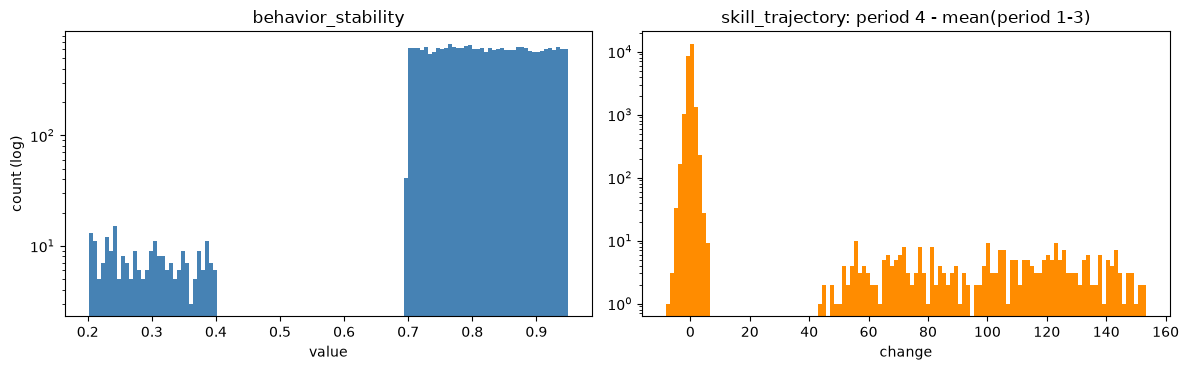

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))

axes[0].hist(df["behavior_stability"].dropna(), bins=120, color="steelblue")
axes[0].set_yscale("log")
axes[0].set_title("behavior_stability")
axes[0].set_xlabel("value")
axes[0].set_ylabel("count (log)")

# ช่วง 4 เทียบกับค่าเฉลี่ยช่วง 1-3
jump = df["skill_trajectory_4"] - df[["skill_trajectory_1", "skill_trajectory_2", "skill_trajectory_3"]].mean(axis=1)
axes[1].hist(jump.dropna(), bins=120, color="darkorange")
axes[1].set_yscale("log")
axes[1].set_title("skill_trajectory: period 4 - mean(period 1-3)")
axes[1].set_xlabel("change")

plt.tight_layout()
plt.show()

**รูปที่ 1** การกระจายของ `behavior_stability` (ซ้าย) และการเปลี่ยนแปลงของ `skill_trajectory` ในช่วงที่ 4 (ขวา) แกน y เป็น log scale

- ซ้าย: คนส่วนใหญ่อยู่ช่วง 0.70–0.95 แต่มีกลุ่มเล็ก ๆ ที่ค่าต่ำกว่า 0.40 แยกออกไปชัดเจน **ระหว่าง 0.40–0.70 ไม่มีบัญชีเลย**
- ขวา: เกือบทุกบัญชีเปลี่ยนแปลงใกล้ 0 แต่มีกลุ่มหนึ่งที่ skill พุ่งขึ้นมากในช่วงสุดท้ายและแยกเป็นก้อนของตัวเอง

ข้อสังเกตนี้เป็นไอเดียหลักของ notebook: **บัญชีผิดปกติแต่ละชนิดจะเป็นกลุ่มย่อยที่มี "ช่องว่าง" คั่นจากคนปกติ**
ถ้าหาช่องว่างนี้ได้อัตโนมัติ ก็ไม่ต้องเดาว่าควร flag กี่ % (โจทย์นี้ไม่มี label ให้ปรับ threshold)

## 3. สร้างสถิติต่อบัญชี

สำหรับ feature ที่มี 4 ช่วง สร้าง 2 ค่า
- `_med` = median ของ 4 ช่วง → พฤติกรรมปกติของบัญชีนั้น (เช่น bot ที่ล็อกอินจาก IP เดิมตลอด)
- `_jump` = ช่วง 4 − ค่าเฉลี่ยช่วง 1–3 → การเปลี่ยนแปลงกะทันหัน (เช่น บัญชีโดนขโมยแล้วคนใหม่เข้ามาเล่น)

feature คงที่ (`account_age_days`, `behavior_stability`, ...) ใช้ค่าเดิม

In [6]:
def build_stats(data):
    stats = {}
    for c in static_cols:
        stats[c] = data[c]
    for b in bases:
        p = data[[f"{b}_{i}" for i in range(1, 5)]]
        stats[f"{b}_med"] = p.median(axis=1)  # median ข้าม NaN ให้เอง
        stats[f"{b}_jump"] = p.iloc[:, 3] - p.iloc[:, :3].mean(axis=1)
    return pd.DataFrame(stats)


S = build_stats(df)
print(S.shape)

(25889, 64)


## 4. หาช่องว่าง (gap) ที่หางของการกระจาย

สำหรับสถิติแต่ละตัว
1. เรียงค่าจากน้อยไปมาก แล้วดูเฉพาะหางซ้ายและขวา ข้างละไม่เกิน 5%
2. หาระยะห่างระหว่างค่าที่ติดกันที่กว้างที่สุดในหางนั้น
3. ถ้าช่องว่างกว้างอย่างน้อย 0.2 เท่าของ IQR ถือว่ากลุ่มที่อยู่ปลายหาง "แยกตัว" จริง ตัดที่กึ่งกลางช่องว่าง

ใช้ IQR เพื่อให้เทียบกันได้ทุก feature ไม่ว่าหน่วยจะเป็นอะไร (มิลลิวินาที, บาท, องศา ...)
พารามิเตอร์เป็นค่าทั่วไปที่ตั้งไว้ก่อน ไม่ได้ปรับจากผลบน leaderboard (หัวข้อ 6 จะเช็คว่าเปลี่ยนค่าแล้วผลเปลี่ยนไหม)

In [7]:
MAX_TAIL = 0.05    # ดูหางข้างละไม่เกิน 5%
MIN_TAIL = 0.002   # กลุ่มต้องมีอย่างน้อย 0.2% ของข้อมูล กัน outlier เดี่ยว ๆ
MIN_GAP = 0.2      # ช่องว่างต้อง >= 0.2 * IQR
MIN_UNIQUE = 200   # ข้าม feature ที่ไม่ต่อเนื่อง เช่น 0/1

In [8]:
def find_gaps(values, max_tail=MAX_TAIL, min_gap=MIN_GAP):
    v = np.sort(values.dropna().values)
    n = len(v)
    iqr = np.percentile(v, 75) - np.percentile(v, 25)
    if iqr <= 0:
        return []

    gaps = np.diff(v)
    tail = int(max_tail * n)
    small = int(MIN_TAIL * n)

    result = []
    for side, start, end in [("low", small, tail), ("high", n - tail - 1, n - small - 1)]:
        k = start + np.argmax(gaps[start:end])  # ช่องว่างที่กว้างที่สุดในหางนี้
        if gaps[k] / iqr >= min_gap:
            threshold = (v[k] + v[k + 1]) / 2
            result.append((side, threshold, gaps[k] / iqr))
    return result

In [9]:
def detect_groups(stats, max_tail=MAX_TAIL, min_gap=MIN_GAP):
    rows = []
    for c in stats.columns:
        if stats[c].nunique() < MIN_UNIQUE:
            continue
        for side, thr, ratio in find_gaps(stats[c], max_tail, min_gap):
            mask = stats[c] < thr if side == "low" else stats[c] > thr
            rows.append({"stat": c, "side": side, "threshold": thr,
                         "n": int(mask.sum()), "gap_iqr": round(ratio, 3)})
    return pd.DataFrame(rows)


def make_flag(stats, groups):
    flag = np.zeros(len(stats), dtype=bool)
    for _, g in groups.iterrows():
        if g["side"] == "low":
            flag |= (stats[g["stat"]] < g["threshold"]).values
        else:
            flag |= (stats[g["stat"]] > g["threshold"]).values
    return flag

In [10]:
groups = detect_groups(S)
flag = make_flag(S, groups)

print("จำนวนกลุ่มที่เจอ:", len(groups))
print(f"บัญชีที่ถูก flag: {flag.sum()} ({flag.mean():.2%})")
groups.sort_values("gap_iqr", ascending=False)

จำนวนกลุ่มที่เจอ: 19
บัญชีที่ถูก flag: 1808 (6.98%)


,stat,side,threshold,n,gap_iqr
18,skill_trajectory_jump,high,25.365272,299,53.350
5,friend_removes_jump,high,8.800406,297,33.565
3,currency_transfers_jump,high,6.883202,293,6.027
15,purchase_frequency_jump,high,3.823755,189,4.590
10,login_lon_jump,low,-16.481163,69,4.419
17,skill_rating_jump,high,401.237022,293,3.821
8,login_lat_jump,low,-15.404825,67,3.167
11,login_lon_jump,high,18.928562,362,2.994
7,location_changes_jump,high,1.917787,493,2.482
0,behavior_stability,low,0.549916,246,2.413


NaN เทียบกับ threshold แล้วได้ False เสมอ บัญชีที่ค่าหายจึงไม่ถูก flag จากสถิติตัวนั้น แต่ยังถูกจับได้จากสถิติตัวอื่น

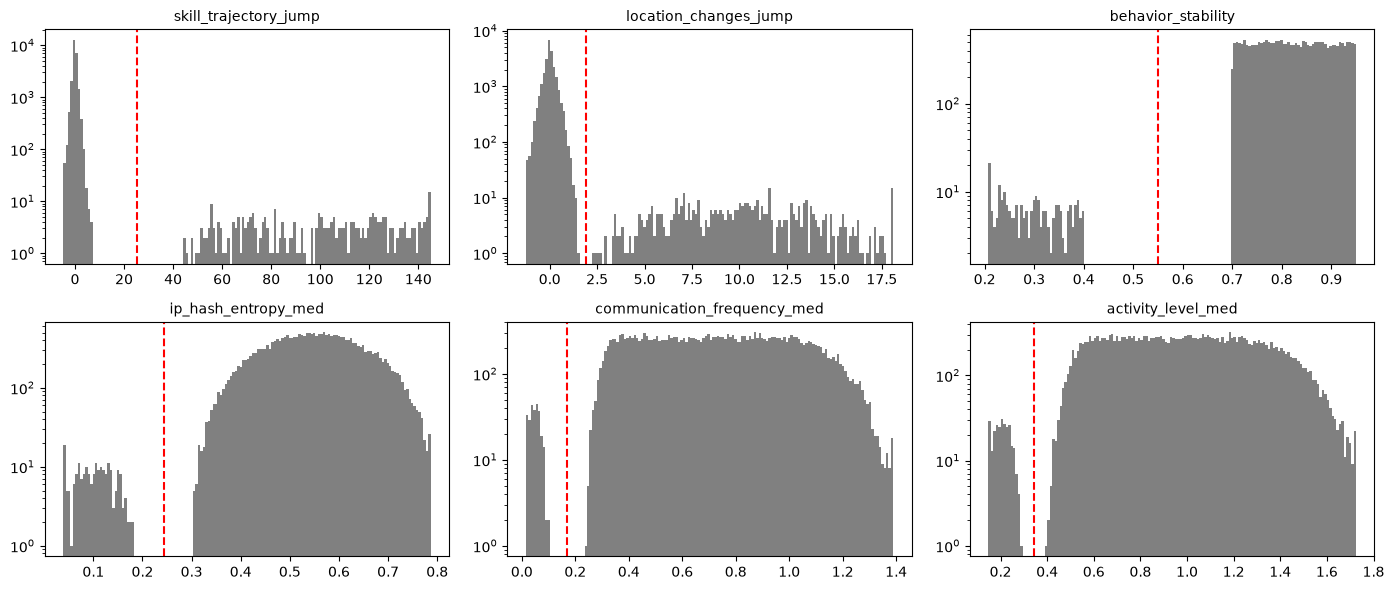

In [11]:
show = ["skill_trajectory_jump", "location_changes_jump", "behavior_stability",
        "ip_hash_entropy_med", "communication_frequency_med", "activity_level_med"]

fig, axes = plt.subplots(2, 3, figsize=(14, 6))
for ax, c in zip(axes.ravel(), show):
    v = S[c].dropna()
    v = v.clip(v.quantile(0.0005), v.quantile(0.9995))  # ตัดค่าสุดโต่งมาก ๆ ออกเพื่อให้กราฟอ่านง่าย
    ax.hist(v, bins=150, color="gray")
    ax.set_yscale("log")
    for _, g in groups[groups["stat"] == c].iterrows():
        ax.axvline(g["threshold"], color="red", ls="--")
    ax.set_title(c, fontsize=10)
plt.tight_layout()
plt.show()

**รูปที่ 2** ตัวอย่างสถิติ 6 ตัวที่เจอกลุ่มแยก เส้นประแดงคือ threshold ที่กึ่งกลางช่องว่าง (แกน y เป็น log scale)

- `skill_trajectory_jump` และ `location_changes_jump` (2 รูปแรก) มีกลุ่มเล็กทางขวาที่เปลี่ยนแปลงมากผิดปกติในช่วงที่ 4
- อีก 4 รูป (`behavior_stability`, `ip_hash_entropy_med`, `communication_frequency_med`, `activity_level_med`) มีกลุ่มที่ค่าต่ำผิดปกติแยกออกไปทางซ้าย
- ช่องว่างของ activity_level แคบที่สุด (0.227×IQR) แต่ยังผ่านเกณฑ์ 0.2

## 5. ตีความกลุ่มที่เจอ

หลายสถิติชี้ไปที่บัญชีชุดเดียวกัน เช่น IP entropy ต่ำ, เวลาล็อกอินสม่ำเสมอ และความยาว session คงที่ เป็นบัญชีกลุ่มเดียวกัน (ลักษณะ bot)
จึงรวมเป็น 5 ชนิดตามความหมาย

In [12]:
def group_mask(stat, side="low"):
    return make_flag(S, groups[(groups["stat"] == stat) & (groups["side"] == side)])


jump_groups = groups[groups["stat"].str.endswith("_jump")]

types = pd.DataFrame({
    "sudden change (period 4)": make_flag(S, jump_groups),
    "low behavior_stability": group_mask("behavior_stability"),
    "bot-like (same IP / regular)": group_mask("ip_hash_entropy_med")
                                    | group_mask("login_time_variance_med")
                                    | group_mask("session_duration_std_med"),
    "no communication": group_mask("communication_frequency_med"),
    "very low activity": group_mask("activity_level_med"),
})

print(types.sum())
print("รวม 5 ชนิดแล้วเท่ากับ flag ทั้งหมด:", (types.any(axis=1).values == flag).all())

sudden change (period 4)        827
low behavior_stability          246
bot-like (same IP / regular)    207
no communication                263
very low activity               265
dtype: int64
รวม 5 ชนิดแล้วเท่ากับ flag ทั้งหมด: True


In [13]:
# ตารางซ้อนทับ: นอกแนวทแยง = จำนวนบัญชีที่อยู่ 2 ชนิดพร้อมกัน
t = types.astype(int)
t.T.dot(t)

,sudden change (period 4),low behavior_stability,bot-like (same IP / regular),no communication,very low activity
sudden change (period 4),827,0,0,0,0
low behavior_stability,0,246,0,0,0
bot-like (same IP / regular),0,0,207,0,0
no communication,0,0,0,263,0
very low activity,0,0,0,0,265


ตัวเลขนอกแนวทแยงเป็น 0 ทั้งหมด แต่ละบัญชีเป็นความผิดปกติแค่ชนิดเดียว 5 ชนิดนี้จึงเป็นกลุ่มที่แยกกันจริง ไม่ได้นับบัญชีเดียวกันซ้ำ

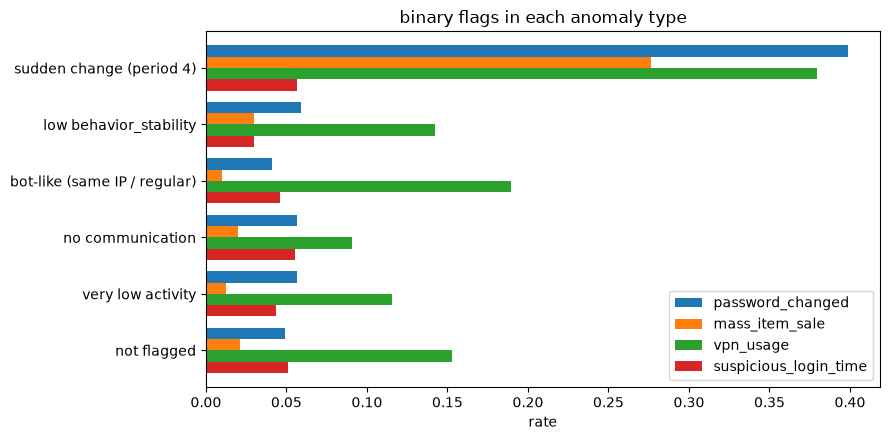

,password_changed,mass_item_sale,vpn_usage,suspicious_login_time
sudden change (period 4),0.399,0.277,0.379,0.057
low behavior_stability,0.059,0.030,0.142,0.030
bot-like (same IP / regular),0.041,0.010,0.190,0.046
no communication,0.057,0.020,0.091,0.055
very low activity,0.057,0.012,0.116,0.044
not flagged,0.049,0.021,0.153,0.051


In [14]:
flag_cols = ["password_changed", "mass_item_sale", "vpn_usage", "suspicious_login_time"]

rates = {name: df.loc[types[name].values, flag_cols].mean() for name in types.columns}
rates["not flagged"] = df.loc[~flag, flag_cols].mean()
rates = pd.DataFrame(rates).T

rates.plot(kind="barh", figsize=(9, 4.5), width=0.8)
plt.xlabel("rate")
plt.title("binary flags in each anomaly type")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()
rates.round(3)

**รูปที่ 3** สัดส่วนของ flag ระดับบัญชีที่ระบบมีอยู่แล้ว (`password_changed`, `mass_item_sale`, `vpn_usage`, `suspicious_login_time`) แยกตามชนิดความผิดปกติ เทียบกับบัญชีที่ไม่ถูก flag

- ชนิด **sudden change** มี `password_changed` ≈ 40% และ `mass_item_sale` ≈ 28% สูงกว่าบัญชีปกติ (≈ 5% และ 2%) ประมาณ 8–13 เท่า
  ตรงกับรูปแบบ **account takeover**: เปลี่ยนรหัส → พฤติกรรมเปลี่ยนทันที → เทขายไอเทม
- ชนิดอื่น ๆ มีค่า flag ใกล้เคียงบัญชีปกติ แปลว่า **rule-based flag เดิมของระบบจับไม่ได้** แต่ยังเห็นได้จากพฤติกรรมที่แยกตัว
  ตรงกับปัญหาในโจทย์ที่ระบบเดิมพลาดผู้โจมตีที่แนบเนียนและ bot ที่ค่อย ๆ ทำงาน

## 6. เช็คความไวต่อพารามิเตอร์

ไม่มี label ให้ validate จึงเช็คแทนว่าถ้าเปลี่ยน `MAX_TAIL` และ `MIN_GAP` แล้วชุดบัญชีที่ flag เปลี่ยนมากแค่ไหน
(ตารางนี้ใช้ดูความเสถียรเท่านั้น ไม่ได้ใช้เลือกค่า)

In [15]:
rows = []
for mt in [0.03, 0.05, 0.07]:
    for mg in [0.15, 0.2, 0.3]:
        f2 = make_flag(S, detect_groups(S, mt, mg))
        jaccard = (f2 & flag).sum() / (f2 | flag).sum()
        rows.append({"max_tail": mt, "min_gap": mg, "n_flag": int(f2.sum()), "jaccard_vs_main": round(jaccard, 4)})
pd.DataFrame(rows)

,max_tail,min_gap,n_flag,jaccard_vs_main
0,0.03,0.15,1808,1.0000
1,0.03,0.20,1808,1.0000
2,0.03,0.30,1543,0.8534
3,0.05,0.15,1808,1.0000
4,0.05,0.20,1808,1.0000
5,0.05,0.30,1543,0.8534
6,0.07,0.15,1808,1.0000
7,0.07,0.20,1808,1.0000
8,0.07,0.30,1543,0.8534


ทุกค่าที่ `min_gap` ≤ 0.2 ได้ผลเหมือนเดิมทุกแถว (Jaccard = 1) ไม่ว่าจะดูหางกว้าง 3%, 5% หรือ 7%
พอเข้มขึ้นเป็น 0.3 กลุ่ม very low activity (gap 0.227) จะหลุดไป ผลจึงเสถียรในช่วงกว้าง ไม่ได้ขึ้นกับการจูนค่าเฉพาะจุด

## 7. เทียบกับ Isolation Forest

สไลด์แนะนำ Isolation Forest / One-Class SVM / Autoencoder จึงลอง Isolation Forest บนสถิติชุดเดียวกัน
(เติม missing ด้วย median และ standardize ก่อน) แล้วเอาบัญชีที่ score สูงสุด 1,808 อันดับ (เท่ากับจำนวนที่ gap method flag) มาเทียบ

In [16]:
X = S.fillna(S.median())
X = StandardScaler().fit_transform(X)

iso = IsolationForest(n_estimators=300, random_state=SEED, n_jobs=-1)
iso.fit(X)
iso_score = -iso.score_samples(X)  # ยิ่งมากยิ่งผิดปกติ

top_n = int(flag.sum())
iso_top = np.zeros(len(S), dtype=bool)
iso_top[np.argsort(-iso_score)[:top_n]] = True
print(f"Isolation Forest top-{top_n} ตรงกับ gap flag: {(iso_top & flag).sum()} บัญชี")

Isolation Forest top-1808 ตรงกับ gap flag: 1020 บัญชี


In [17]:
iso_rank = pd.Series(iso_score).rank(ascending=False).values
compare = pd.DataFrame({
    "n": types.sum(),
    "caught by IF top-1808": [(types[c].values & iso_top).sum() for c in types.columns],
    "median IF rank": [np.median(iso_rank[types[c].values]) for c in types.columns],
})
compare

,n,caught by IF top-1808,median IF rank
sudden change (period 4),827,822,414.0
low behavior_stability,246,54,3926.5
bot-like (same IP / regular),207,97,2028.0
no communication,263,25,8086.0
very low activity,265,22,8188.0


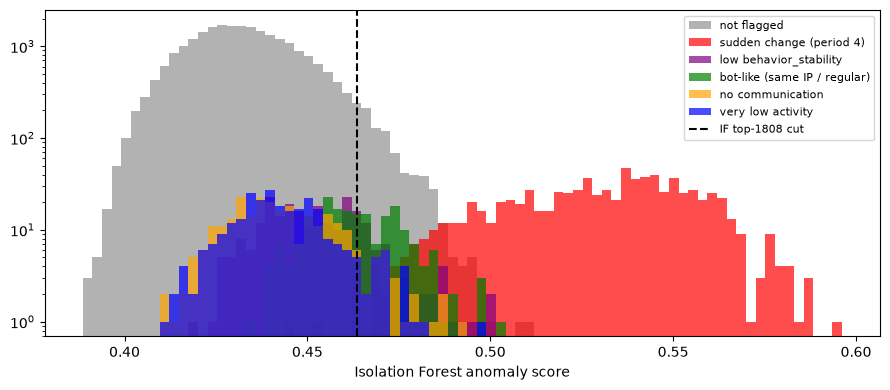

In [18]:
fig, ax = plt.subplots(figsize=(9, 4))
bins = np.linspace(iso_score.min(), iso_score.max(), 80)
ax.hist(iso_score[~flag], bins=bins, alpha=0.6, label="not flagged", color="gray")
for name, color in zip(types.columns, ["red", "purple", "green", "orange", "blue"]):
    ax.hist(iso_score[types[name].values], bins=bins, alpha=0.7, label=name, color=color)
ax.axvline(np.sort(iso_score)[-top_n], color="black", ls="--", label="IF top-1808 cut")
ax.set_yscale("log")
ax.set_xlabel("Isolation Forest anomaly score")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**รูปที่ 4** การกระจายของ Isolation Forest score แยกตามชนิดที่ gap method เจอ เส้นประดำคือจุดตัดถ้าเลือก 1,808 บัญชีที่ score สูงสุด

- Isolation Forest จับชนิด **sudden change** ได้เกือบครบ (822/827) เพราะค่าพุ่งหลาย feature พร้อมกัน ทำให้ถูกแยกได้ง่าย
- แต่ชนิดอื่นที่ผิดปกติแค่ **feature เดียว** (เช่น no communication, very low activity) มี score ปนอยู่กลางกลุ่มปกติ
  เพราะเมื่อมีกว่า 200 มิติ ค่าต่ำผิดปกติเพียงมิติเดียวมีผลต่อ score น้อย
- รวมแล้ว IF top-1808 ทับกับ gap flag เพียง 1,020 บัญชี ส่วนอีก ~790 อันดับที่เหลือของ IF เป็นบัญชีที่ "แปลกนิดหน่อยหลายมิติ" แต่ไม่ได้แยกเป็นกลุ่ม

จึงเลือก gap method เป็นคำตอบสุดท้าย เพราะ (1) จับได้ทั้ง 5 ชนิด (2) จำนวน flag มาจากโครงสร้างข้อมูลเอง ไม่ต้องตั้ง contamination
และ (3) อธิบายได้ว่าบัญชีไหนโดน flag เพราะอะไร ซึ่งทีม security เอาไปใช้ตรวจต่อได้ทันที

## 8. สร้างไฟล์ submission

id ใน submission (`ANS00001` ...) เรียงตามลำดับแถวของ `test.csv` ถ้ามี `sample_submission.csv` จะใช้ id จากไฟล์นั้นแทน

In [19]:
sample_path = ROOT / "data" / "raw" / "sample_submission.csv"
if sample_path.exists():
    ids = pd.read_csv(sample_path)["id"].values
else:
    ids = [f"ANS{i:05d}" for i in range(1, len(df) + 1)]

assert len(ids) == len(df)

sub = pd.DataFrame({"id": ids, "task5": flag.astype(int)})
out_path = ROOT / "submissions" / "task5.csv"
out_path.parent.mkdir(parents=True, exist_ok=True)
sub.to_csv(out_path, index=False)

print(out_path.relative_to(ROOT), sub.shape)
print(sub["task5"].value_counts())

submissions\task5.csv (25889, 2)
task5
0    24081
1     1808
Name: count, dtype: int64


In [20]:
# เช็คกับไฟล์รวมที่ส่ง Kaggle จริง (ถ้ามีในเครื่อง)
final_path = ROOT / "submissions" / "final_submission.csv"
if final_path.exists():
    final = pd.read_csv(final_path)
    same = (final["id"].values == sub["id"].values).all() and (final["task5"].values == sub["task5"].values).all()
    print("task5 ตรงกับไฟล์ที่ส่ง Kaggle ทุกแถว:", same)
else:
    print("ไม่มี final_submission.csv ข้ามการเช็ค")

task5 ตรงกับไฟล์ที่ส่ง Kaggle ทุกแถว: True


## สรุป

- พบความผิดปกติ 5 ชนิดที่ไม่ซ้อนกัน รวม **1,808 บัญชี (6.98%)**: sudden change ในช่วง 4 (827), behavior_stability ต่ำ (246),
  bot-like (207), ไม่สื่อสารเลย (263) และ activity ต่ำมาก (265)
- จำนวน flag ได้มาจาก "ช่องว่าง" ในข้อมูลเอง ไม่ได้กำหนด % ล่วงหน้า และผลเหมือนเดิมเมื่อเปลี่ยนพารามิเตอร์ในช่วงกว้าง
- Isolation Forest จับได้ดีเฉพาะชนิดที่ผิดปกติหลาย feature พร้อมกัน ส่วนชนิดที่ผิดปกติ feature เดียวกลับหลุด

**ข้อจำกัด:** ไม่มี label จึงวัด F3 ในเครื่องไม่ได้ และวิธีนี้จับเฉพาะกลุ่มที่แยกตัวชัดเจน
ถ้ามีบัญชีผิดปกติที่ค่อย ๆ เปลี่ยนจนกลืนกับคนปกติ วิธีนี้จะมองไม่เห็น